# Анализ данных, обучение моделей и метрики

Ноутбук дает рабочий цикл эксперимента: первичный EDA, подготовка train/validation, обучение baseline-моделей, сравнение метрик и разбор ошибок. Обучение выполняется только на train, выбор модели — только на validation. Official test читается только при аудите пересечений и не участвует в обучении или подборе.

Меняйте параметры в ячейке конфигурации и запускайте ноутбук сверху вниз. Каждый запуск сохраняет сводные результаты, отчеты по классам, матрицы ошибок, сериализованные модели и записи MLflow в проекте.

## 1. Подключение проекта и библиотек

In [1]:
from pathlib import Path
import json
import sys
import time
import joblib
import mlflow
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, precision_recall_fscore_support
import sklearn

def find_project_root(start=Path.cwd()):
    for candidate in (start, *start.parents):
        if (candidate / 'configs' / 'baseline.json').exists() and (candidate / 'src').is_dir():
            return candidate
    raise FileNotFoundError('Не найдена папка проекта с configs/baseline.json')

ROOT = find_project_root()
sys.path.insert(0, str(ROOT / 'src'))
from models.baseline import build_models
CONFIG_PATH = ROOT / 'configs' / 'baseline.json'
DATA_DIR = ROOT / 'data' / 'processed'
OUT_DIR = ROOT / 'experiments' / 'baseline'
MODEL_DIR = ROOT / 'work' / 'notebook_models'
OUT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)
print(f'Проект: {ROOT}')
print(f'Python: {sys.version.split()[0]} | scikit-learn: {sklearn.__version__}')

C:\Users\maks5\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Проект: C:\Users\maks5\Documents\Codex\2026-11-13\x20
Python: 3.14.3 | scikit-learn: 1.9.1


## 2. Первичный анализ датасета (EDA)

Ноутбук проверит исходные файлы по SHA-256, покажет пропуски, баланс классов, длины запросов, повторы и пересечения формулировок. Если исходных файлов нет, EDA покажет доступную подготовленную выборку.

{
  "splits": {
    "train": {
      "rows": 10003,
      "classes": 77,
      "missing": {
        "text": 0,
        "category": 0
      },
      "class_min": 35,
      "class_max": 187,
      "median_chars": 47.0,
      "p95_chars": 151.89999999999964,
      "duplicates": {
        "exact_duplicate_rows": 0,
        "exact_duplicate_values": 0,
        "normalized_duplicate_rows": 8,
        "normalized_duplicate_values": 4
      }
    },
    "test": {
      "rows": 3080,
      "classes": 77,
      "missing": {
        "text": 0,
        "category": 0
      },
      "class_min": 40,
      "class_max": 40,
      "median_chars": 45.0,
      "p95_chars": 124.0,
      "duplicates": {
        "exact_duplicate_rows": 0,
        "exact_duplicate_values": 0,
        "normalized_duplicate_rows": 2,
        "normalized_duplicate_values": 1
      }
    }
  },
  "cross_split": {
    "exact_text_overlap_unique": 0,
    "normalized_overlap_unique": 7,
    "normalized_overlapping_train_rows": 7,
 

,split,rows,classes,missing,median_chars,normalized_duplicate_rows
0,train,10003,77,0,47.0,8
1,test,3080,77,0,45.0,2


,exact_text_overlap_unique,normalized_overlap_unique,normalized_overlapping_train_rows,normalized_overlapping_test_rows,label_conflicts_on_normalized_overlap
0,0,7,7,7,0


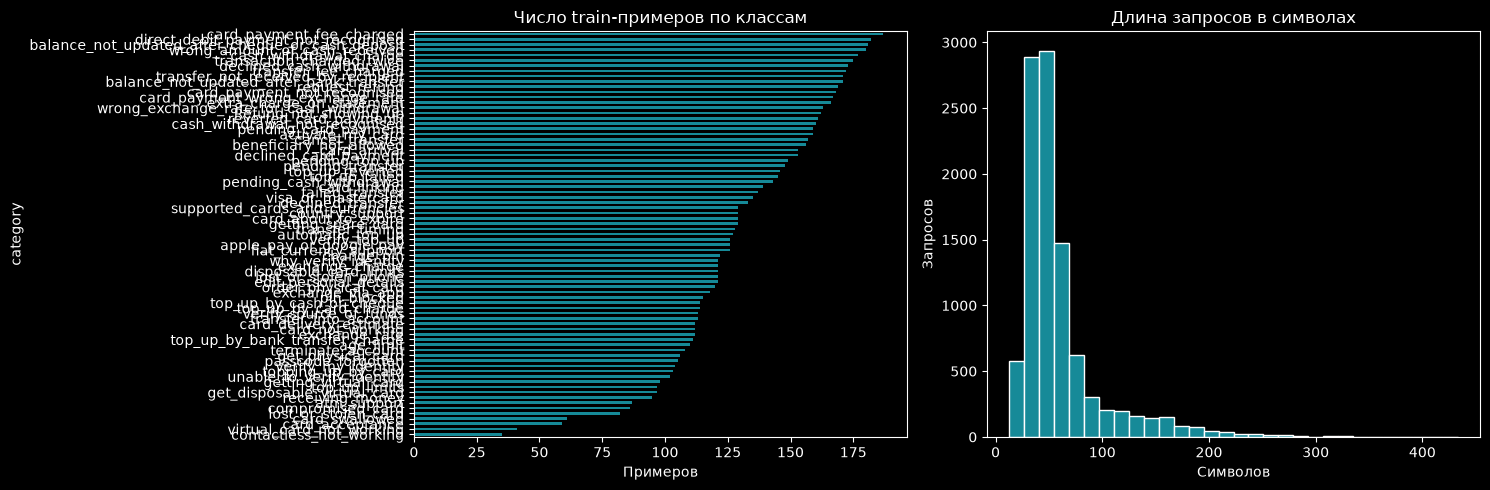

,text,category
0,I am still waiting on my card?,card_arrival
1,What can I do if my card still hasn't arrived ...,card_arrival
2,I have been waiting over a week. Is the card s...,card_arrival
3,Can I track my card while it is in the process...,card_arrival
4,"How do I know if I will get my card, or if it ...",card_arrival


In [2]:
import runpy
raw_train = ROOT / 'data' / 'raw' / 'train.csv'
raw_test = ROOT / 'data' / 'raw' / 'test.csv'
if raw_train.exists() and raw_test.exists():
    eda_module = runpy.run_path(str(ROOT / 'src' / 'data' / 'eda.py'))
    eda_module['main']()
    eda_train_df = pd.read_csv(raw_train)
    eda_summary = json.loads((ROOT / 'reports' / 'eda_summary.json').read_text(encoding='utf-8'))
    display(pd.DataFrame([{'split': name, 'rows': values['rows'], 'classes': values['n_classes'], 'missing': sum(values['missing_by_column'].values()), 'median_chars': values['text_length']['characters']['0.5'], 'normalized_duplicate_rows': values['duplicates']['normalized_duplicate_rows']} for name, values in eda_summary['splits'].items()]))
    display(pd.DataFrame([eda_summary['cross_split']]))
else:
    processed_train_path = ROOT / 'data' / 'processed' / 'train.csv'
    if not processed_train_path.exists():
        raise FileNotFoundError('Для EDA добавьте BANKING77 train.csv и test.csv в data/raw.')
    print('Исходные CSV отсутствуют; строю обзор подготовленной train-выборки.')
    eda_train_df = pd.read_csv(processed_train_path)

class_counts = eda_train_df['category'].value_counts().sort_values()
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
class_counts.plot(kind='barh', ax=axes[0], color='#168A98', title='Число train-примеров по классам')
axes[0].set_xlabel('Примеров')
text_lengths = eda_train_df['text'].astype(str).str.len()
axes[1].hist(text_lengths, bins=30, color='#168A98', edgecolor='white')
axes[1].set_title('Длина запросов в символах')
axes[1].set_xlabel('Символов')
axes[1].set_ylabel('Запросов')
fig.tight_layout()
plt.show()
display(eda_train_df.head())

## 3. Проверка конфигурации и подготовка выборок

Если сырые файлы уже находятся в `data/raw/`, эта ячейка повторно создаст воспроизводимое разбиение. Очистка исключает дубликаты и совпадения с official test по нормализованному тексту; метки test не участвуют в обучении и выборе модели.

In [3]:
config = json.loads(CONFIG_PATH.read_text(encoding='utf-8-sig'))
raw_train = ROOT / 'data' / 'raw' / 'train.csv'
raw_test = ROOT / 'data' / 'raw' / 'test.csv'
if raw_train.exists() and raw_test.exists():
    import runpy
    split_module = runpy.run_path(str(ROOT / 'src' / 'data' / 'prepare_splits.py'))
    split_module['main']()
else:
    print('Исходные CSV не найдены; использую уже подготовленные data/processed файлы.')

train_path = DATA_DIR / 'train.csv'
validation_path = DATA_DIR / 'validation.csv'
if not train_path.exists() or not validation_path.exists():
    raise FileNotFoundError('Не найдены train.csv/validation.csv. Положите исходные CSV в data/raw и повторите ячейку.')
train_df = pd.read_csv(train_path)
validation_df = pd.read_csv(validation_path)
required_columns = {'text', 'category'}
assert required_columns.issubset(train_df.columns) and required_columns.issubset(validation_df.columns)
assert train_df[list(required_columns)].notna().all().all()
assert validation_df[list(required_columns)].notna().all().all()
assert set(train_df['category']) == set(validation_df['category'])

display(pd.DataFrame({'split': ['train', 'validation'], 'rows': [len(train_df), len(validation_df)], 'classes': [train_df.category.nunique(), validation_df.category.nunique()]}))
display(train_df.head())

{
  "removed_internal_duplicates": 4,
  "removed_test_overlaps_from_train": 7,
  "clean_train": 9992,
  "train": 7993,
  "validation": 1999,
  "classes": 77,
  "train_support_min_max": [
    28,
    149
  ],
  "validation_support_min_max": [
    7,
    38
  ],
  "official_test_unchanged": true,
  "manifest": "C:\\Users\\maks5\\Documents\\Codex\\2026-11-13\\x20\\experiments\\baseline\\split_manifest.json"
}


,split,rows,classes
0,train,7993,77
1,validation,1999,77


,text,category
0,How do I see my updated balance after I make a...,balance_not_updated_after_cheque_or_cash_deposit
1,What currencies can I have?,fiat_currency_support
2,I don't remember my login code,passcode_forgotten
3,Is there anything to do because my phone was s...,lost_or_stolen_phone
4,There's a direct debit payment that I don't re...,direct_debit_payment_not_recognised


## 4. Настройки эксперимента

Параметры ниже можно изменить перед повторным обучением. Модельный pipeline включает TF-IDF внутри fit, чтобы словарь строился только по train.

In [4]:
experiment_name = config['tracking']['experiment']
tracking_db = ROOT / config['tracking']['database']
mlflow.set_tracking_uri(f"sqlite:///{tracking_db.as_posix()}")
mlflow.set_experiment(experiment_name)

X_train = train_df['text'].astype(str)
y_train = train_df['category'].astype(str)
X_val = validation_df['text'].astype(str)
y_val = validation_df['category'].astype(str)
labels = sorted(y_train.unique())
models = build_models(config)
print(f'Эксперимент MLflow: {experiment_name}')
print(f'Моделей к обучению: {len(models)} | train: {len(X_train):,} | validation: {len(X_val):,}')
display(pd.DataFrame([{'model': name, 'estimator': repr(model)[:180]} for name, model in models.items()]))

Эксперимент MLflow: banking77-classical-baselines
Моделей к обучению: 4 | train: 7,993 | validation: 1,999


,model,estimator
0,majority,DummyClassifier(strategy='most_frequent')
1,tfidf_logistic_regression,"Pipeline(steps=[('tfidf',\n Tf..."
2,tfidf_linear_svm,"Pipeline(steps=[('tfidf',\n Tf..."
3,tfidf_multinomial_nb,"Pipeline(steps=[('tfidf',\n Tf..."


## 5. Обучение и оценка

Для каждой модели рассчитываются accuracy, macro/weighted precision, recall и F1. Macro F1 усредняет качество по классам и используется для сортировки. Модели и артефакты сохраняются локально, а параметры и метрики логируются в MLflow.

In [5]:
results = []
predictions = {}
reports = {}
fitted_models = {}
for name, model in models.items():
    start = time.perf_counter()
    model.fit(X_train, y_train)
    fit_seconds = time.perf_counter() - start
    y_pred = np.asarray(model.predict(X_val))
    predictions[name] = y_pred
    fitted_models[name] = model
    report = classification_report(y_val, y_pred, labels=labels, output_dict=True, zero_division=0)
    reports[name] = pd.DataFrame(report).T
    macro_p, macro_r, macro_f1, _ = precision_recall_fscore_support(y_val, y_pred, labels=labels, average='macro', zero_division=0)
    weighted_p, weighted_r, weighted_f1, _ = precision_recall_fscore_support(y_val, y_pred, labels=labels, average='weighted', zero_division=0)
    metrics = {'accuracy': accuracy_score(y_val, y_pred), 'macro_precision': macro_p, 'macro_recall': macro_r, 'macro_f1': macro_f1, 'weighted_precision': weighted_p, 'weighted_recall': weighted_r, 'weighted_f1': weighted_f1, 'fit_seconds': fit_seconds}
    model_path = MODEL_DIR / f'{name}.joblib'
    joblib.dump(model, model_path)
    reports[name].to_csv(OUT_DIR / f'{name}_classification_report.csv', index_label='label')
    confusion = pd.DataFrame(confusion_matrix(y_val, y_pred, labels=labels), index=labels, columns=labels)
    confusion.to_csv(OUT_DIR / f'{name}_confusion_matrix.csv', index_label='true_label')
    with mlflow.start_run(run_name=name) as run:
        mlflow.log_params({'model': name, 'sklearn_version': sklearn.__version__, 'train_rows': len(X_train), 'validation_rows': len(X_val), 'tfidf_ngram_range': str(config['tfidf']['ngram_range']), 'tfidf_min_df': config['tfidf']['min_df']})
        mlflow.set_tags({'dataset': 'BANKING77', 'evaluation_split': 'validation', 'workflow': 'jupyter_notebook'})
        mlflow.log_metrics({key: float(value) for key, value in metrics.items()})
        mlflow.log_artifact(str(model_path), artifact_path='serialized_model')
        mlflow.log_artifact(str(OUT_DIR / f'{name}_classification_report.csv'), artifact_path='evaluation')
        metrics['mlflow_run_id'] = run.info.run_id
    results.append({'model': name, **{key: float(value) for key, value in metrics.items() if key != 'mlflow_run_id'}, 'mlflow_run_id': metrics['mlflow_run_id']})

results_df = pd.DataFrame(results).sort_values('macro_f1', ascending=False).reset_index(drop=True)
results_df.to_csv(OUT_DIR / 'notebook_results.csv', index=False)
display(results_df.style.format(precision=4).highlight_max(subset=['accuracy', 'macro_f1', 'weighted_f1'], color='#d7f2df'))
print(f'Сводка записана: {OUT_DIR / "notebook_results.csv"}')

2026/11/13 18:44:41 WARNING mlflow.utils.git_utils: Failed to import Git (the Git executable is probably not on your PATH), so Git SHA is not available. Error: Failed to initialize: Bad git executable.
The git executable must be specified in one of the following ways:
    - be included in your $PATH
    - be set via $GIT_PYTHON_GIT_EXECUTABLE
    - explicitly set via git.refresh(<full-path-to-git-executable>)

All git commands will error until this is rectified.

This initial message can be silenced or aggravated in the future by setting the
$GIT_PYTHON_REFRESH environment variable. Use one of the following values:
    - quiet|q|silence|s|silent|none|n|0: for no message or exception
    - warn|w|warning|log|l|1: for a warning message (logging level CRITICAL, displayed by default)
    - error|e|exception|raise|r|2: for a raised exception

Example:
    export GIT_PYTHON_REFRESH=quiet

2026/11/13 18:44:41 WARNING mlflow.utils.git_utils: Failed to import Git (the Git executable is probably

,model,accuracy,macro_precision,macro_recall,macro_f1,weighted_precision,weighted_recall,weighted_f1,fit_seconds,mlflow_run_id
0,tfidf_linear_svm,0.8789,0.8870,0.8776,0.8795,0.8836,0.8789,0.8786,0.5796,0c6e4d371f464358937b98c9ead6e34b
1,tfidf_logistic_regression,0.8469,0.8627,0.8339,0.8395,0.8553,0.8469,0.8454,11.8038,0c0c2a334c39442eb8774a0dde6c04ef
2,tfidf_multinomial_nb,0.7989,0.8032,0.7610,0.7632,0.8119,0.7989,0.7901,0.2142,337b0fc528ad4b08938a95a66e4f3d98
3,majority,0.0190,0.0002,0.0130,0.0005,0.0004,0.0190,0.0007,0.0045,1da226faf82e40369e2a63648f1d20a3


Сводка записана: C:\Users\maks5\Documents\Codex\2026-11-13\x20\experiments\baseline\notebook_results.csv


## 6. Подбор параметров Linear SVM

Проверяются три диапазона TF-IDF n-грамм, три значения C и два режима весов классов. Все варианты обучаются на том же train и сравниваются на той же validation. Рейтинг строится по Macro F1; official test не используется.

Измените списки параметров ниже, чтобы сформулировать следующий эксперимент. Результаты каждого варианта появятся в таблице и сохранятся в CSV и MLflow.

In [6]:
from itertools import product
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC

ngram_ranges = [(1, 1), (1, 2), (1, 3)]
C_values = [0.5, 1.0, 2.0]
class_weight_values = [None, 'balanced']
tuning_dir = OUT_DIR / 'tuning_reports'
tuning_dir.mkdir(parents=True, exist_ok=True)
tuning_rows = []

for ngram_range, C, class_weight in product(ngram_ranges, C_values, class_weight_values):
    weight_tag = 'none' if class_weight is None else class_weight
    name = f"svm_ngram_{ngram_range[0]}-{ngram_range[1]}_C-{C:g}_weight-{weight_tag}"
    vectorizer = TfidfVectorizer(
        ngram_range=ngram_range,
        min_df=config['tfidf']['min_df'],
        sublinear_tf=config['tfidf']['sublinear_tf'],
        lowercase=config['tfidf']['lowercase'],
        stop_words=config['tfidf']['stop_words'],
        token_pattern=config['tfidf']['token_pattern'],
    )
    model = Pipeline([
        ('tfidf', vectorizer),
        ('classifier', LinearSVC(C=C, class_weight=class_weight, random_state=config['linear_svm']['random_state'])),
    ])
    start = time.perf_counter()
    model.fit(X_train, y_train)
    fit_seconds = time.perf_counter() - start
    y_pred = np.asarray(model.predict(X_val))
    report = pd.DataFrame(classification_report(y_val, y_pred, labels=labels, output_dict=True, zero_division=0)).T
    report_path = tuning_dir / f'{name}_classification_report.csv'
    report.to_csv(report_path, index_label='label')
    macro_p, macro_r, macro_f1, _ = precision_recall_fscore_support(y_val, y_pred, labels=labels, average='macro', zero_division=0)
    weighted_p, weighted_r, weighted_f1, _ = precision_recall_fscore_support(y_val, y_pred, labels=labels, average='weighted', zero_division=0)
    metrics = {
        'accuracy': accuracy_score(y_val, y_pred),
        'macro_precision': macro_p,
        'macro_recall': macro_r,
        'macro_f1': macro_f1,
        'weighted_precision': weighted_p,
        'weighted_recall': weighted_r,
        'weighted_f1': weighted_f1,
        'fit_seconds': fit_seconds,
    }
    model_path = MODEL_DIR / f'{name}.joblib'
    joblib.dump(model, model_path)
    with mlflow.start_run(run_name=name) as run:
        mlflow.log_params({
            'model': 'LinearSVC',
            'tfidf_ngram_min': ngram_range[0],
            'tfidf_ngram_max': ngram_range[1],
            'tfidf_min_df': config['tfidf']['min_df'],
            'C': C,
            'class_weight': weight_tag,
            'sklearn_version': sklearn.__version__,
        })
        mlflow.set_tags({'dataset': 'BANKING77', 'evaluation_split': 'validation', 'workflow': 'parameter_search'})
        mlflow.log_metrics({key: float(value) for key, value in metrics.items()})
        mlflow.log_artifact(str(report_path), artifact_path='evaluation')
        mlflow.log_artifact(str(model_path), artifact_path='serialized_model')
        run_id = run.info.run_id
    result = {
        'model': name,
        'tfidf_ngram_range': str(ngram_range),
        'C': C,
        'class_weight': weight_tag,
        **{key: float(value) for key, value in metrics.items()},
        'mlflow_run_id': run_id,
    }
    tuning_rows.append(result)
    results.append(result)
    predictions[name] = y_pred
    reports[name] = report
    fitted_models[name] = model

tuning_results_df = pd.DataFrame(tuning_rows).sort_values('macro_f1', ascending=False).reset_index(drop=True)
tuning_results_df.to_csv(OUT_DIR / 'linear_svm_tuning_results.csv', index=False)
results_df = pd.DataFrame(results).sort_values('macro_f1', ascending=False).reset_index(drop=True)
results_df.to_csv(OUT_DIR / 'notebook_results.csv', index=False)
display(tuning_results_df.head(10).style.format(precision=4).highlight_max(subset=['accuracy', 'macro_f1', 'weighted_f1'], color='#d7f2df'))
print(f'Проверено конфигураций: {len(tuning_results_df)}')
print(f'Таблица подбора: {OUT_DIR / "linear_svm_tuning_results.csv"}')
print(f'Лучшая конфигурация: {tuning_results_df.iloc[0]["model"]}')

Rank,TF-IDF ngrams,C,Class weight,Accuracy,Macro F1
1,"(1, 2)",1.0,none,0.8789,0.8795
2,"(1, 2)",2.0,none,0.8774,0.8793
3,"(1, 1)",2.0,balanced,0.8784,0.8765
4,"(1, 2)",2.0,balanced,0.8764,0.8763
5,"(1, 2)",1.0,balanced,0.8759,0.8751
6,"(1, 1)",2.0,none,0.8764,0.8750
7,"(1, 1)",1.0,balanced,0.8764,0.8745
8,"(1, 1)",1.0,none,0.8749,0.8731
9,"(1, 1)",0.5,none,0.8739,0.8713
10,"(1, 1)",0.5,balanced,0.8704,0.8693


Проверено конфигураций: 18
Таблица подбора: experiments/baseline/linear_svm_tuning_results.csv
Лучшая конфигурация: svm_ngram_1-2_C-1_weight-none


## 6. Словесные и символьные n-граммы

Гипотеза: символьные n-граммы помогут различать близкие формулировки и опечатки. Сравниваются char, char_wb и объединение word TF-IDF с char_wb. Для каждого представления Linear SVM обучается на том же train и оценивается на той же validation.

Official test не используется. Результаты добавляются в общий рейтинг и сохраняются в MLflow и CSV.

In [7]:
from sklearn.pipeline import FeatureUnion

char_candidates = [
    {'representation': 'char_wb', 'C': 0.5},
    {'representation': 'char_wb', 'C': 1.0},
    {'representation': 'char_wb', 'C': 2.0},
    {'representation': 'char', 'C': 1.0},
    {'representation': 'word_char_wb', 'C': 0.5},
    {'representation': 'word_char_wb', 'C': 1.0},
    {'representation': 'word_char_wb', 'C': 2.0},
]
char_report_dir = OUT_DIR / 'character_tuning_reports'
char_report_dir.mkdir(parents=True, exist_ok=True)
char_rows = []

def make_text_features(representation):
    tfidf = config['tfidf']
    if representation == 'char_wb':
        return TfidfVectorizer(analyzer='char_wb', ngram_range=(3, 5), min_df=2, lowercase=tfidf['lowercase'], sublinear_tf=tfidf['sublinear_tf'])
    if representation == 'char':
        return TfidfVectorizer(analyzer='char', ngram_range=(3, 5), min_df=2, lowercase=tfidf['lowercase'], sublinear_tf=tfidf['sublinear_tf'])
    word = TfidfVectorizer(ngram_range=tuple(tfidf['ngram_range']), min_df=tfidf['min_df'], sublinear_tf=tfidf['sublinear_tf'], lowercase=tfidf['lowercase'], stop_words=tfidf['stop_words'], token_pattern=tfidf['token_pattern'])
    char = TfidfVectorizer(analyzer='char_wb', ngram_range=(3, 5), min_df=2, lowercase=tfidf['lowercase'], sublinear_tf=tfidf['sublinear_tf'])
    return FeatureUnion([('word_tfidf', word), ('char_wb_tfidf', char)])

for candidate in char_candidates:
    representation, C = candidate['representation'], candidate['C']
    name = f"svm_{representation}_C-{C:g}"
    model = Pipeline([
        ('tfidf', make_text_features(representation)),
        ('classifier', LinearSVC(C=C, class_weight=None, random_state=config['linear_svm']['random_state'])),
    ])
    start = time.perf_counter()
    model.fit(X_train, y_train)
    fit_seconds = time.perf_counter() - start
    y_pred = np.asarray(model.predict(X_val))
    report = pd.DataFrame(classification_report(y_val, y_pred, labels=labels, output_dict=True, zero_division=0)).T
    report_path = char_report_dir / f'{name}_classification_report.csv'
    report.to_csv(report_path, index_label='label')
    macro_p, macro_r, macro_f1, _ = precision_recall_fscore_support(y_val, y_pred, labels=labels, average='macro', zero_division=0)
    weighted_p, weighted_r, weighted_f1, _ = precision_recall_fscore_support(y_val, y_pred, labels=labels, average='weighted', zero_division=0)
    metrics = {
        'accuracy': accuracy_score(y_val, y_pred),
        'macro_precision': macro_p,
        'macro_recall': macro_r,
        'macro_f1': macro_f1,
        'weighted_precision': weighted_p,
        'weighted_recall': weighted_r,
        'weighted_f1': weighted_f1,
        'fit_seconds': fit_seconds,
    }
    model_path = MODEL_DIR / f'{name}.joblib'
    joblib.dump(model, model_path)
    with mlflow.start_run(run_name=name) as run:
        mlflow.log_params({'model': 'LinearSVC', 'feature_representation': representation, 'char_ngram_range': '3-5', 'char_min_df': 2, 'C': C, 'class_weight': 'none', 'sklearn_version': sklearn.__version__})
        mlflow.set_tags({'dataset': 'BANKING77', 'evaluation_split': 'validation', 'workflow': 'representation_comparison'})
        mlflow.log_metrics({key: float(value) for key, value in metrics.items()})
        mlflow.log_artifact(str(report_path), artifact_path='evaluation')
        mlflow.log_artifact(str(model_path), artifact_path='serialized_model')
        run_id = run.info.run_id
    result = {'model': name, 'feature_representation': representation, 'C': C, **{key: float(value) for key, value in metrics.items()}, 'mlflow_run_id': run_id}
    char_rows.append(result)
    results.append(result)
    predictions[name] = y_pred
    reports[name] = report
    fitted_models[name] = model

char_results_df = pd.DataFrame(char_rows).sort_values('macro_f1', ascending=False).reset_index(drop=True)
char_results_df.to_csv(OUT_DIR / 'character_ngram_results.csv', index=False)
reference = results_df.loc[results_df['model'] == 'tfidf_linear_svm'].iloc[0]
comparison_rows = [{'model': 'tfidf_linear_svm', 'feature_representation': 'word (1,2)', 'C': 1.0, 'accuracy': reference['accuracy'], 'macro_f1': reference['macro_f1'], 'fit_seconds': reference['fit_seconds']}] + char_rows
word_char_comparison_df = pd.DataFrame(comparison_rows).sort_values('macro_f1', ascending=False).reset_index(drop=True)
word_char_comparison_df.to_csv(OUT_DIR / 'word_char_comparison.csv', index=False)
results_df = pd.DataFrame(results).sort_values('macro_f1', ascending=False).reset_index(drop=True)
results_df.to_csv(OUT_DIR / 'notebook_results.csv', index=False)
display(word_char_comparison_df.style.format(precision=4).highlight_max(subset=['accuracy', 'macro_f1'], color='#d7f2df'))
print(f'Проверено новых представлений: {len(char_results_df)}')
print(f'Лучшая конфигурация: {word_char_comparison_df.iloc[0]["model"]}')
print(f'Сравнение сохранено: {OUT_DIR / "word_char_comparison.csv"}')

Model,Feature representation,C,Accuracy,Macro F1,Fit (s)
svm_word_char_wb_C-2,word_char_wb,2,0.8974,0.8987,3.86
svm_word_char_wb_C-1,word_char_wb,1,0.8974,0.8986,2.74
svm_word_char_wb_C-0.5,word_char_wb,0.5,0.8984,0.8975,2.69
svm_char_C-1,char,1,0.8959,0.8954,3.63
svm_char_wb_C-1,char_wb,1,0.8919,0.8921,1.83
svm_char_wb_C-2,char_wb,2,0.8894,0.8898,3.84
svm_char_wb_C-0.5,char_wb,0.5,0.8859,0.8844,1.70
tfidf_linear_svm,"word (1,2)",1,0.8789,0.8795,0.56


Проверено новых представлений: 7
Лучшая конфигурация: svm_word_char_wb_C-2
Сравнение сохранено: experiments/baseline/word_char_comparison.csv


## 7. Разбор лучшей модели и ошибок

Выбор лучшей модели выполняется по Macro F1 на validation. После изменения конфигурации или данных снова выполните ячейку обучения перед этим разделом.

In [8]:
best_name = results_df.iloc[0]['model']
best_model = fitted_models[best_name]
best_pred = predictions[best_name]
print(f'Лучшая модель по validation Macro F1: {best_name} ({results_df.iloc[0]["macro_f1"]:.4f})')
display(reports[best_name].loc[labels].sort_values('f1-score').head(15))

mistakes = validation_df.loc[y_val.to_numpy() != best_pred].copy()
mistakes['predicted_category'] = best_pred[y_val.to_numpy() != best_pred]
mistakes.to_csv(OUT_DIR / 'notebook_best_model_mistakes.csv', index=False)
confusions = mistakes.groupby(['category', 'predicted_category']).size().sort_values(ascending=False).rename('count').reset_index()
confusions.to_csv(OUT_DIR / 'notebook_top_confusions.csv', index=False)
display(confusions.head(20))
display(mistakes.head(20))
print(f'Ошибки сохранены в: {OUT_DIR / "notebook_best_model_mistakes.csv"}')

Лучшая модель по validation Macro F1: svm_word_char_wb_C-2 (0.8987)


                                    precision    recall  f1-score  support
label                                                                     
top_up_failed                        0.833333  0.689655  0.754717     29.0
pending_transfer                     0.909091  0.666667  0.769231     30.0
lost_or_stolen_card                  0.857143  0.750000  0.800000     16.0
card_payment_not_recognised          0.818182  0.794118  0.805970     34.0
failed_transfer                      0.766667  0.851852  0.807018     27.0
compromised_card                     0.750000  0.882353  0.810811     17.0
pending_top_up                       0.764706  0.866667  0.812500     30.0
exchange_rate                        0.818182  0.818182  0.818182     22.0
transfer_timing                      0.840000  0.807692  0.823529     26.0
top_up_by_bank_transfer_charge       0.791667  0.863636  0.826087     22.0
transfer_not_received_by_recipient   0.805556  0.852941  0.828571     34.0
card_arrival             

                           category                      predicted_category  count
                      top_up_failed                          pending_top_up      4
                   pending_transfer      transfer_not_received_by_recipient      4
                   pending_transfer                    pending_card_payment      4
direct_debit_payment_not_recognised             card_payment_not_recognised      3
            beneficiary_not_allowed                         failed_transfer      3
                 topping_up_by_card                          pending_top_up      3
                   activate_my_card                     order_physical_card      2
        card_payment_not_recognised     direct_debit_payment_not_recognised      2
              declined_card_payment                    pending_card_payment      2
                  declined_transfer                         failed_transfer      2
     top_up_by_bank_transfer_charge                    transfer_fee_charged      2
   c

                                                                                                                                                                              text                                category                               predicted_category
                                                                                                                      Why hasn't my account updated to reflect my current balance? balance_not_updated_after_bank_transfer balance_not_updated_after_cheque_or_cash_deposit
                                                                                                                   How is this transfer supposed to work? It's not working for me.                         failed_transfer                                 card_not_working
                                                                                                                                                            Will a cheque suffice?                to

Ошибки сохранены в: experiments/baseline/notebook_best_model_mistakes.csv


## 8. Матрица ошибок и следующие шаги

Матрица содержит все классы и поэтому может быть большой. В таблице выше показаны наиболее частые пары путаницы. Для production перед выкладкой дополнительно нужны отдельный финальный test, контроль качества входных данных, API и мониторинг; этот ноутбук отвечает за воспроизводимые эксперименты и сравнение моделей.

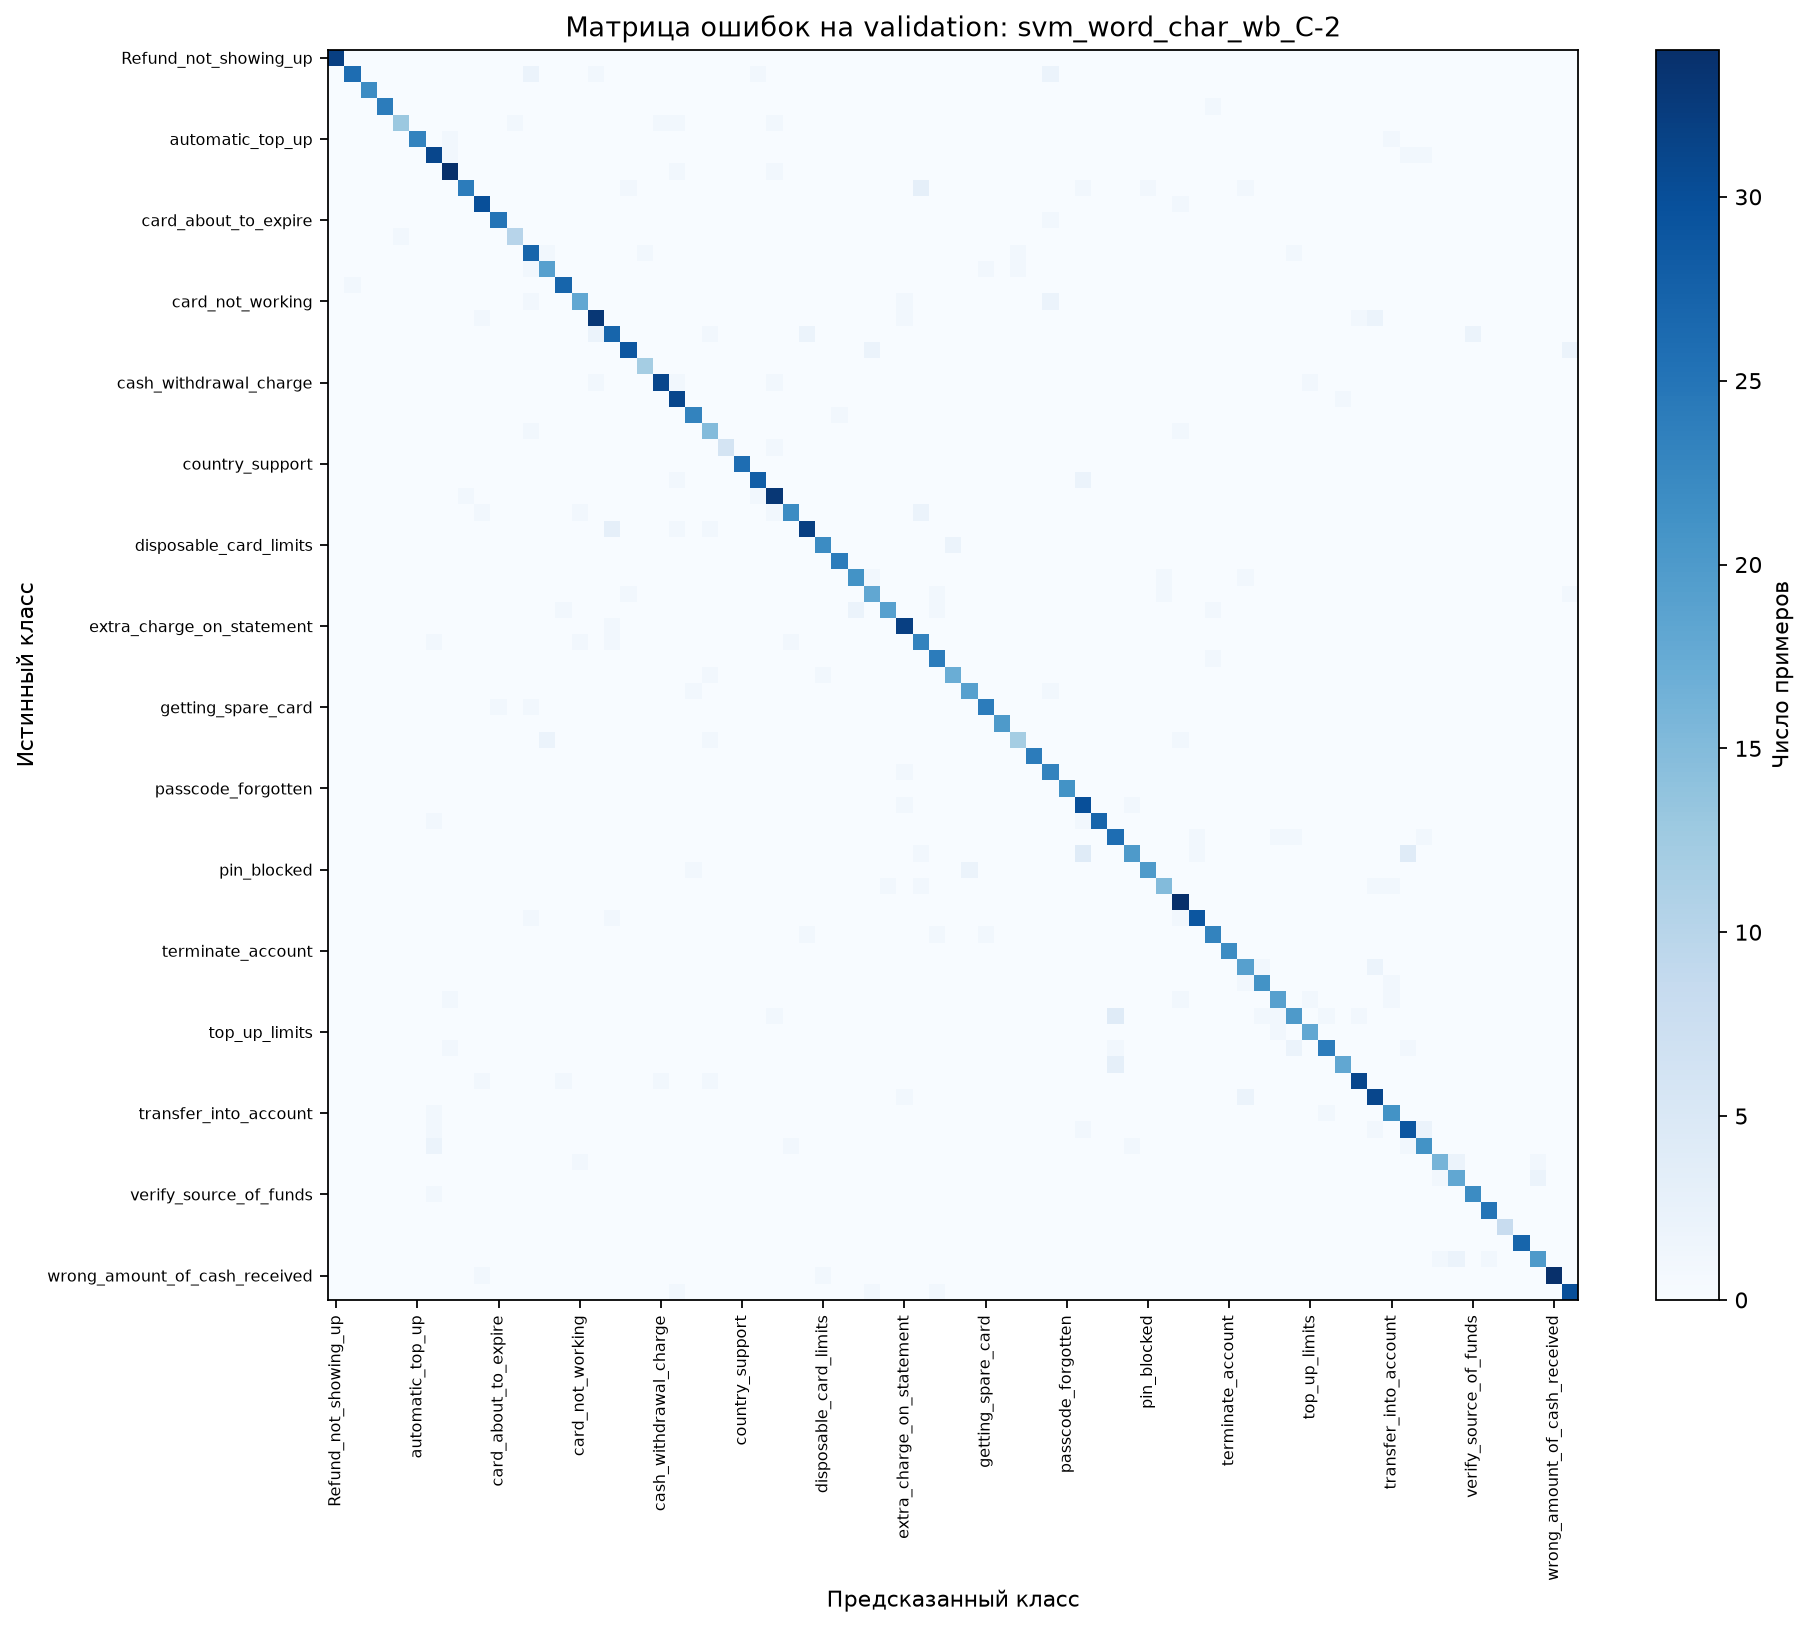

Матрица сохранена: C:\Users\maks5\Documents\Codex\2026-11-13\x20\experiments\baseline\notebook_best_model_confusion_matrix.png
Модели сохранены в: C:\Users\maks5\Documents\Codex\2026-11-13\x20\work\notebook_models
MLflow database: C:\Users\maks5\Documents\Codex\2026-11-13\x20\mlflow.db


In [9]:
matrix = confusion_matrix(y_val, best_pred, labels=labels)
fig, ax = plt.subplots(figsize=(12, 10))
image = ax.imshow(matrix, interpolation='nearest', cmap='Blues')
ticks = np.arange(0, len(labels), 5)
ax.set_xticks(ticks, [labels[i] for i in ticks], rotation=90, fontsize=7)
ax.set_yticks(ticks, [labels[i] for i in ticks], fontsize=7)
ax.set_xlabel('Предсказанный класс')
ax.set_ylabel('Истинный класс')
ax.set_title(f'Матрица ошибок на validation: {best_name}')
fig.colorbar(image, ax=ax, label='Число примеров')
fig.tight_layout()
matrix_path = OUT_DIR / 'notebook_best_model_confusion_matrix.png'
fig.savefig(matrix_path, dpi=160, bbox_inches='tight')
plt.show()
print(f'Матрица сохранена: {matrix_path}')
print(f'Модели сохранены в: {MODEL_DIR}')
print(f'MLflow database: {tracking_db}')

## 9. Фиксация кандидата и замеры эксплуатации

Кандидат и параметры уже зафиксированы в `configs/final_model.json`. На validation измеряются latency одного вызова, пакетное время и размер joblib. Замеры не включают HTTP/API и потребление RAM. Official test остаётся закрытым до отдельного финального шага.

In [10]:
import statistics
from pathlib import Path

final_config_path = ROOT / 'configs' / 'final_model.json'
final_config = json.loads(final_config_path.read_text(encoding='utf-8'))
candidate_name = 'svm_word_char_wb_C-2'
if candidate_name in fitted_models:
    candidate_model = fitted_models[candidate_name]
else:
    candidate_model = joblib.load(MODEL_DIR / f'{candidate_name}.joblib')

final_model_path = ROOT / final_config['model_artifact']
final_model_path.parent.mkdir(parents=True, exist_ok=True)
joblib.dump(candidate_model, final_model_path)
benchmark = final_config['benchmark']
warmup_count = min(benchmark['warmup_requests'], len(X_val))
candidate_model.predict(X_val.iloc[:warmup_count])
latency_queries = X_val.iloc[:min(benchmark['latency_sample_size'], len(X_val))].tolist()
latency_samples = []
for _ in range(benchmark['latency_repeats']):
    for query in latency_queries:
        start = time.perf_counter()
        candidate_model.predict([query])
        latency_samples.append(time.perf_counter() - start)
batch_samples = []
for _ in range(benchmark['batch_repeats']):
    start = time.perf_counter()
    candidate_model.predict(X_val)
    batch_samples.append(time.perf_counter() - start)
median_batch_seconds = statistics.median(batch_samples)
selected_row = word_char_comparison_df.loc[word_char_comparison_df['model'] == candidate_name].iloc[0]
operational_metrics = {
    'model': final_config['name'],
    'validation_rows': int(len(X_val)),
    'validation_macro_f1': float(final_config['selection']['value']),
    'validation_accuracy': float(selected_row['accuracy']),
    'validation_macro_precision': float(selected_row['macro_precision']),
    'validation_macro_recall': float(selected_row['macro_recall']),
    'validation_weighted_f1': float(selected_row['weighted_f1']),
    'fit_seconds_single_run': float(selected_row['fit_seconds']),
    'single_query_latency_p50_ms': float(np.percentile(latency_samples, 50) * 1000),
    'single_query_latency_p95_ms': float(np.percentile(latency_samples, 95) * 1000),
    'batch_validation_seconds_median': float(median_batch_seconds),
    'batch_amortized_ms_per_request': float(median_batch_seconds * 1000 / len(X_val)),
    'batch_validation_throughput_requests_per_second': float(len(X_val) / median_batch_seconds),
    'serialized_model_bytes': int(final_model_path.stat().st_size),
    'serialized_model_mb': float(final_model_path.stat().st_size / (1024 * 1024)),
    'runtime_memory_measured': False,
    'http_overhead_included': False,
    'official_test_evaluated': False,
}
final_results_dir = ROOT / 'experiments' / 'final_model'
final_results_dir.mkdir(parents=True, exist_ok=True)
operational_metrics_path = final_results_dir / 'operational_metrics.json'
with mlflow.start_run(run_name='frozen_candidate_operational_benchmark') as run:
    mlflow.log_params({'model': final_config['name'], 'validation_rows': len(X_val), 'sklearn_version': sklearn.__version__})
    mlflow.set_tags({'dataset': 'BANKING77', 'evaluation_split': 'validation', 'workflow': 'pre_test_candidate_freeze'})
    mlflow.log_metrics({key: float(value) for key, value in operational_metrics.items() if isinstance(value, (int, float)) and not isinstance(value, bool)})
    operational_metrics['mlflow_run_id'] = run.info.run_id
    operational_metrics_path.write_text(json.dumps(operational_metrics, ensure_ascii=False, indent=2), encoding='utf-8')
    mlflow.log_artifact(str(final_config_path), artifact_path='frozen_configuration')
    mlflow.log_artifact(str(operational_metrics_path), artifact_path='benchmark')
    mlflow.log_artifact(str(final_model_path), artifact_path='serialized_model')

display(pd.DataFrame([operational_metrics]).drop(columns=['mlflow_run_id']).T.rename(columns={0: 'value'}))
print(f'Фиксированная конфигурация: {final_config_path}')
print(f'Сериализованный кандидат: {final_model_path}')
print(f'Замеры: {operational_metrics_path}')

Модель: banking77-word-char-tfidf-linear-svm
Macro F1 validation: 0.8987
Accuracy validation: 0.8974
Fit, сек, один прогон: 3.86
Один запрос P50, мс: 1.21
Один запрос P95, мс: 2.20
Пакетная validation, сек: 0.185
Пакетная пропускная способность, запросов/сек: 10791
Joblib размер, MiB: 20.36
RAM измерена: Нет
HTTP overhead включен: Нет
Official test оценивался: Нет

Фиксированная конфигурация: configs/final_model.json
Сериализованный кандидат: work/final_models/banking77_word_char_tfidf_linear_svm.joblib
Замеры: experiments/final_model/operational_metrics.json


## 10. Однократная финальная оценка на official test

Эта ячейка оценивает уже зафиксированную модель. Test используется только для итоговых метрик, не для выбора признаков, параметров или порогов. После просмотра результатов не подстраивайте модель под этот набор.

Чтобы случайно не переоценивать test при повторном запуске, ячейка сначала проверяет сохранённый результат. Если оценка уже выполнена, она показывает сохранённые метрики, не запуская модель повторно.

model: banking77-word-char-tfidf-linear-svm
evaluation_split: official_test
test_rows: 3080
classes: 77
accuracy: 0.9010
macro_precision: 0.9039
macro_recall: 0.9010
macro_f1: 0.9011
weighted_f1: 0.9011
metrics_are_for_final_reporting_only: True

                                  label  precision  recall  f1-score  support
balance_not_updated_after_bank_transfer   0.725000   0.725  0.725000     40.0
                       pending_transfer   0.775000   0.775  0.775000     40.0
                        failed_transfer   0.750000   0.825  0.785714     40.0
                       card_not_working   0.760870   0.875  0.813953     40.0
              unable_to_verify_identity   0.861111   0.775  0.815789     40.0
                          top_up_failed   0.842105   0.800  0.820513     40.0
                            pin_blocked   0.842105   0.800  0.820513     40.0
     transfer_not_received_by_recipient   0.825000   0.825  0.825000     40.0
wrong_exchange_rate_for_cash_withdrawal   0.846154   0.825  0.835443     40.0
                        top_up_reverted   0.888889   0.800  0.842105     40.0

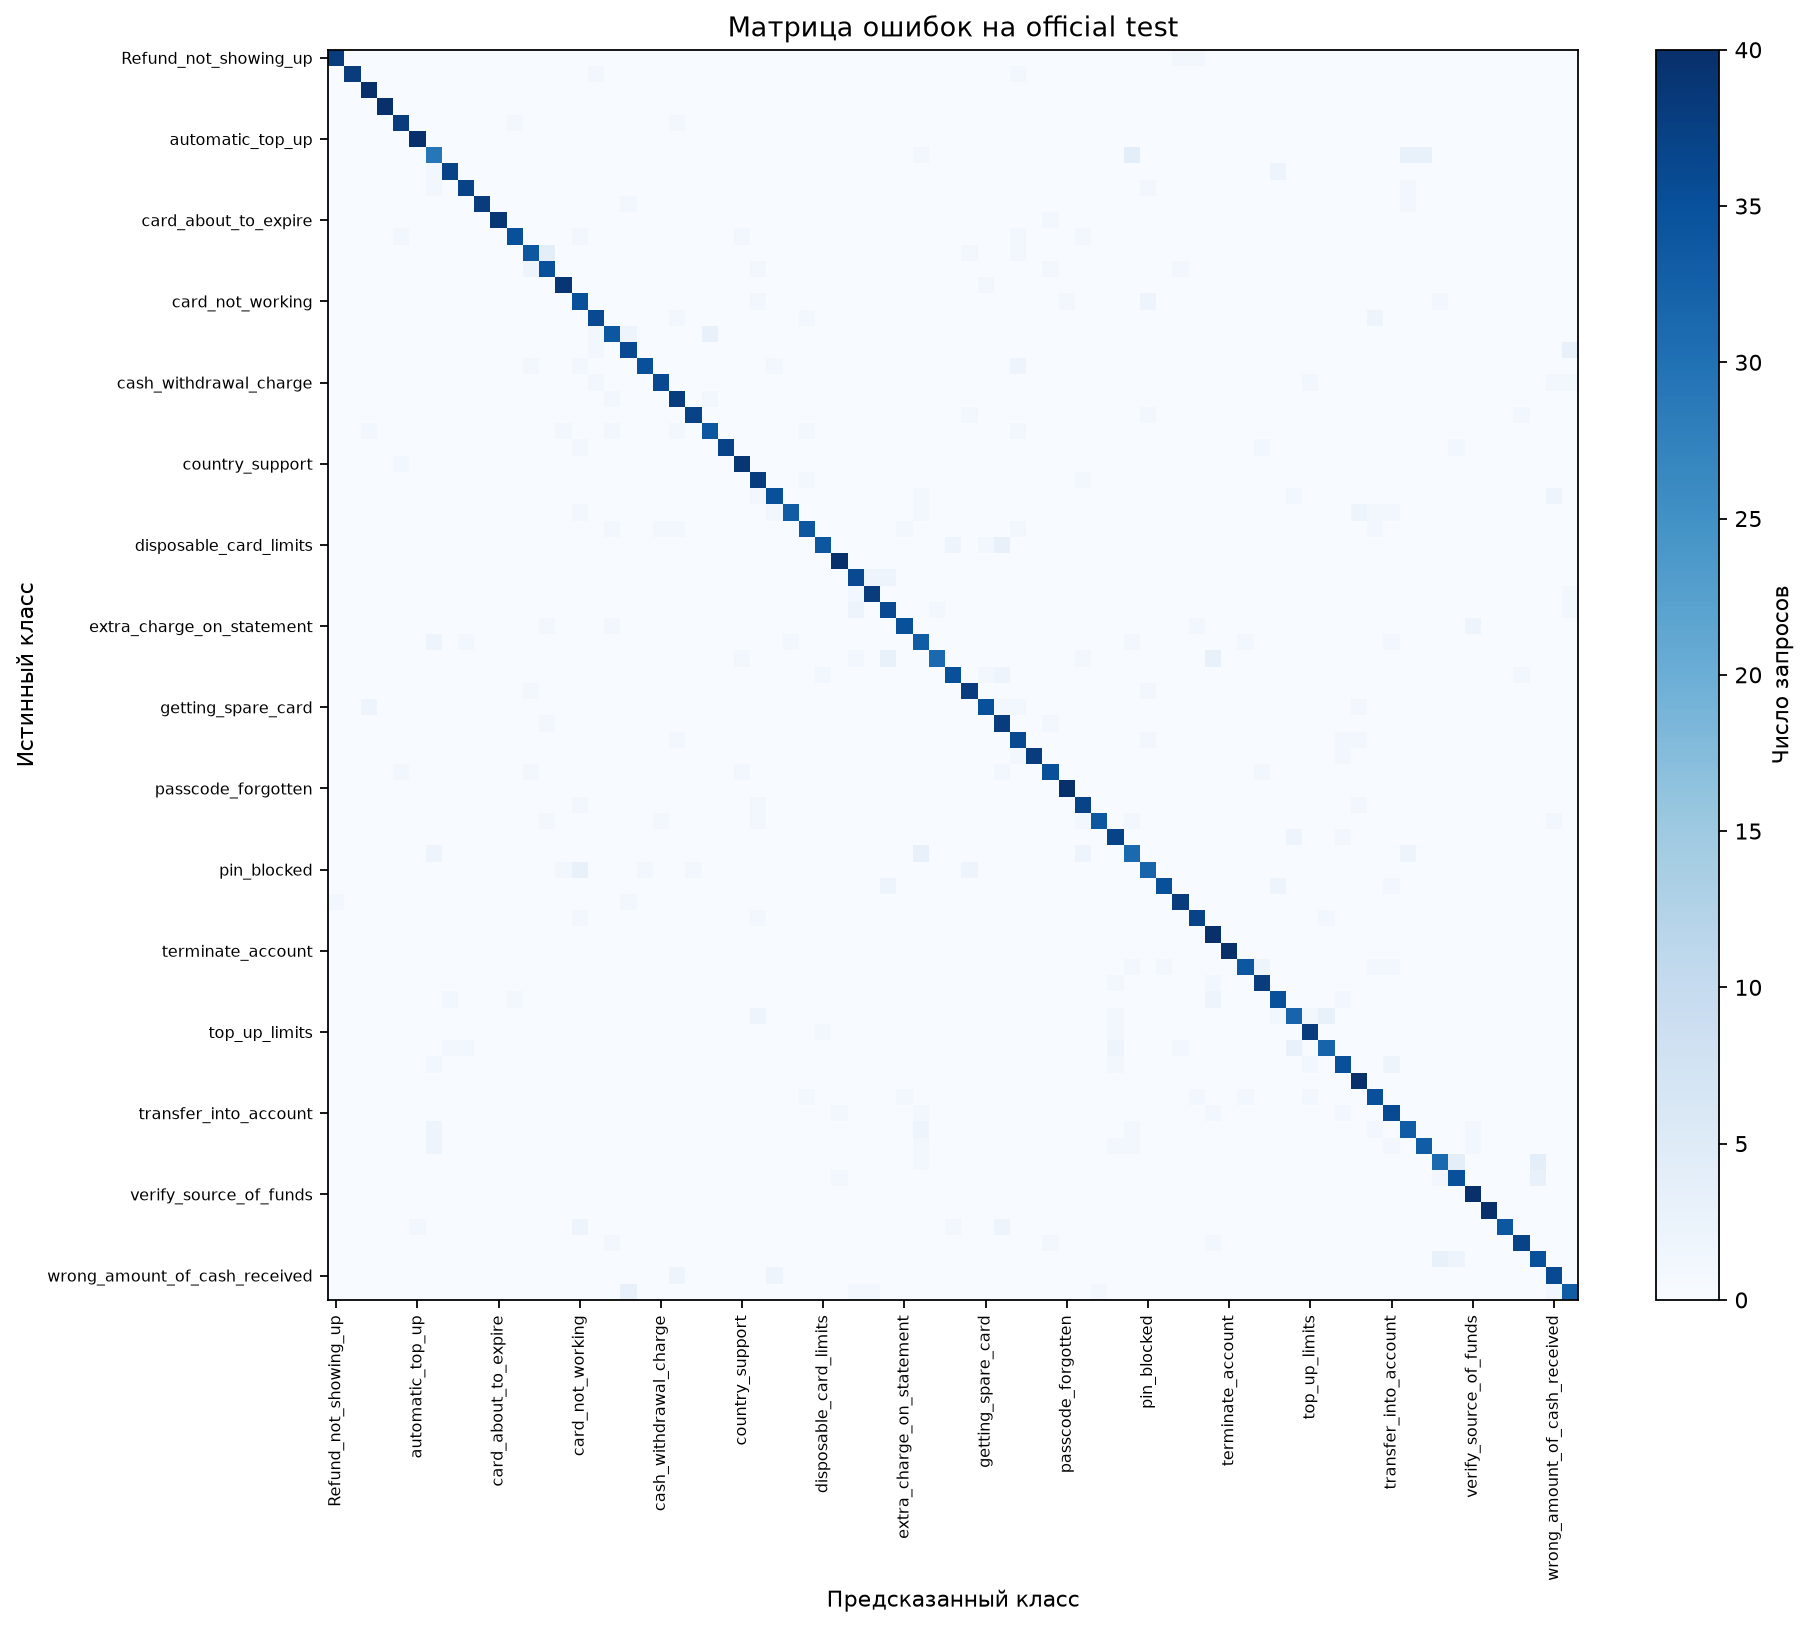

Итоговые метрики: experiments/final_model/test_metrics.json
Отчёт по классам: experiments/final_model/classification_report.csv
Результаты official test не используются для дальнейшего подбора модели.


In [11]:
import hashlib
from sklearn.metrics import precision_recall_fscore_support

final_config_path = ROOT / 'configs' / 'final_model.json'
final_config = json.loads(final_config_path.read_text(encoding='utf-8'))
final_dir = ROOT / 'experiments' / 'final_model'
final_dir.mkdir(parents=True, exist_ok=True)
test_metrics_path = final_dir / 'test_metrics.json'
test_attempt_path = final_dir / 'official_test_evaluation_started.json'
if test_metrics_path.exists():
    official_test_result = json.loads(test_metrics_path.read_text(encoding='utf-8'))
    display(pd.DataFrame([official_test_result]).drop(columns=['mlflow_run_id'], errors='ignore').T.rename(columns={0: 'saved value'}))
    saved_report = pd.read_csv(final_dir / 'classification_report.csv')
    saved_classes = saved_report[~saved_report['label'].isin(['accuracy', 'macro avg', 'weighted avg'])]
    display(saved_classes.sort_values('f1-score').head(10))
    from IPython.display import Image as NotebookImage
    display(NotebookImage(filename=str(final_dir / 'confusion_matrix.png')))
    print('Финальная оценка уже сохранена; повторный вызов модели на official test пропущен.')
else:
    if final_config['selection']['official_test_evaluated']:
        raise RuntimeError('В конфигурации отмечена использованная test-выборка, но файл с результатами не найден. Не запускайте повторную оценку до проверки артефактов.')
    if test_attempt_path.exists():
        raise RuntimeError('Найдена отметка о начатой оценке official test без результата. Не запускайте test повторно; сначала проверьте файлы в experiments/final_model/.')
    test_path = ROOT / 'data' / 'raw' / 'test.csv'
    source_manifest = json.loads((ROOT / 'data' / 'raw' / 'source_manifest.json').read_text(encoding='utf-8'))
    test_sha256 = hashlib.sha256(test_path.read_bytes()).hexdigest()
    expected_sha256 = source_manifest['files']['test.csv']['sha256']
    if test_sha256 != expected_sha256:
        raise ValueError(f'Official test SHA-256 mismatch: {test_sha256}')
    test_attempt_path.write_text(json.dumps({'model': final_config['name'], 'source_test_sha256': test_sha256, 'status': 'started'}, ensure_ascii=False, indent=2), encoding='utf-8')
    test_df = pd.read_csv(test_path)
    if len(test_df) != source_manifest['files']['test.csv']['rows_expected']:
        raise ValueError('Число строк official test не совпадает с манифестом источника.')
    if not test_df['category'].value_counts().eq(40).all():
        raise ValueError('Ожидалось ровно 40 запросов на каждый intent в official test.')
    model_path = ROOT / final_config['model_artifact']
    final_model = joblib.load(model_path)
    y_test = test_df['category'].astype(str)
    test_labels = sorted(y_test.unique())
    y_test_pred = np.asarray(final_model.predict(test_df['text'].astype(str)))
    test_report = classification_report(y_test, y_test_pred, labels=test_labels, output_dict=True, zero_division=0)
    report_path = final_dir / 'classification_report.csv'
    pd.DataFrame(test_report).T.to_csv(report_path, index_label='label')
    test_matrix = pd.DataFrame(confusion_matrix(y_test, y_test_pred, labels=test_labels), index=test_labels, columns=test_labels)
    confusion_path = final_dir / 'confusion_matrix.csv'
    test_matrix.to_csv(confusion_path, index_label='true_label')
    macro_p, macro_r, macro_f1, _ = precision_recall_fscore_support(y_test, y_test_pred, labels=test_labels, average='macro', zero_division=0)
    weighted_p, weighted_r, weighted_f1, _ = precision_recall_fscore_support(y_test, y_test_pred, labels=test_labels, average='weighted', zero_division=0)
    official_test_result = {
        'model': final_config['name'],
        'evaluation_split': 'official_test',
        'test_rows': int(len(test_df)),
        'classes': int(len(test_labels)),
        'accuracy': float(accuracy_score(y_test, y_test_pred)),
        'macro_precision': float(macro_p),
        'macro_recall': float(macro_r),
        'macro_f1': float(macro_f1),
        'weighted_precision': float(weighted_p),
        'weighted_recall': float(weighted_r),
        'weighted_f1': float(weighted_f1),
        'source_test_sha256': test_sha256,
        'metrics_are_for_final_reporting_only': True,
    }
    fig, ax = plt.subplots(figsize=(12, 10))
    image = ax.imshow(test_matrix.to_numpy(), interpolation='nearest', cmap='Blues')
    ticks = np.arange(0, len(test_labels), 5)
    ax.set_xticks(ticks, [test_labels[i] for i in ticks], rotation=90, fontsize=7)
    ax.set_yticks(ticks, [test_labels[i] for i in ticks], fontsize=7)
    ax.set_xlabel('Предсказанный класс')
    ax.set_ylabel('Истинный класс')
    ax.set_title('Матрица ошибок на official test')
    fig.colorbar(image, ax=ax, label='Число запросов')
    fig.tight_layout()
    test_plot_path = final_dir / 'confusion_matrix.png'
    fig.savefig(test_plot_path, dpi=160, bbox_inches='tight')
    plt.show()
    with mlflow.start_run(run_name='final_official_test_evaluation') as run:
        mlflow.log_params({'model': final_config['name'], 'test_rows': len(test_df), 'classes': len(test_labels), 'sklearn_version': sklearn.__version__})
        mlflow.set_tags({'dataset': 'BANKING77', 'evaluation_split': 'official_test', 'purpose': 'final_reporting_only'})
        mlflow.log_metrics({key: value for key, value in official_test_result.items() if isinstance(value, (int, float)) and not isinstance(value, bool)})
        official_test_result['mlflow_run_id'] = run.info.run_id
        test_metrics_path.write_text(json.dumps(official_test_result, ensure_ascii=False, indent=2), encoding='utf-8')
        final_config['selection']['official_test_evaluated'] = True
        final_config['selection']['test_results'] = 'experiments/final_model/test_metrics.json'
        final_config['selection']['test_file_sha256'] = test_sha256
        final_config_path.write_text(json.dumps(final_config, ensure_ascii=False, indent=2) + '\n', encoding='utf-8')
        test_attempt_path.write_text(json.dumps({'model': final_config['name'], 'source_test_sha256': test_sha256, 'status': 'completed', 'results': 'experiments/final_model/test_metrics.json', 'mlflow_run_id': run.info.run_id}, ensure_ascii=False, indent=2), encoding='utf-8')
        for artifact in (test_metrics_path, report_path, confusion_path, test_plot_path, final_config_path):
            mlflow.log_artifact(str(artifact), artifact_path='final_evaluation')
        mlflow.log_artifact(str(model_path), artifact_path='serialized_model')
    display(pd.DataFrame([official_test_result]).drop(columns=['mlflow_run_id']).T.rename(columns={0: 'value'}))
    print(f'Итоговые метрики: {test_metrics_path}')
    print(f'Отчёт по классам: {report_path}')
    print('Результаты official test не используются для дальнейшего подбора модели.')